In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import scipy.sparse as sp
from scipy.sparse.linalg import spsolve
%matplotlib inline

FILES = {"Eyes open": "S001R01.edf", "Eyes closed": "S001R02.edf", "Task": "S001R05.edf"}
CHANNEL = 60

def read_edf(path, channel=60):
    with open(path, "rb") as f:
        h = f.read(256)
        n_rec, dur, ns = int(h[236:244]), float(h[244:252]), int(h[252:256])
        sh = f.read(256 * ns)
        raw = np.frombuffer(f.read(), dtype="<i2")
    fld = lambda off, w: [sh[off + i * w: off + (i + 1) * w].decode().strip() for i in range(ns)]
    pmin, pmax = np.array(fld(104 * ns, 8), float), np.array(fld(112 * ns, 8), float)
    dmin, dmax = np.array(fld(120 * ns, 8), float), np.array(fld(128 * ns, 8), float)
    nsamp = np.array(fld(216 * ns, 8), int)
    raw = raw[: n_rec * nsamp.sum()].reshape(n_rec, nsamp.sum())
    c = channel - 1
    s0 = nsamp[:c].sum()
    x = raw[:, s0:s0 + nsamp[c]].ravel().astype(float)
    x = (x - dmin[c]) * (pmax[c] - pmin[c]) / (dmax[c] - dmin[c]) + pmin[c]
    return x, nsamp[c] / dur

def periodogram(y):
    y = np.asarray(y, float) - np.mean(y)
    n = len(y)
    m = n // 2
    return np.arange(1, m + 1) / n, np.abs(np.fft.fft(y)[1:m + 1]) ** 2 / n

def pen_whittle(I, lam, w=None, iters=200):
    m = len(I)
    w = np.ones(m) if w is None else w
    D = sp.diags([1., -2., 1.], [0, 1, 2], shape=(m - 2, m))
    P = 2 * lam * (D.T @ D)
    obj = lambda t: np.sum(w * (t + I * np.exp(-t))) + lam * np.sum((D @ t) ** 2)
    th = np.full(m, np.log(np.mean(I[w > 0])))
    f0 = obj(th)
    for _ in range(iters):
        e = I * np.exp(-th)
        step = spsolve((sp.diags(w * e) + P).tocsc(), w * (1 - e) + P @ th)
        t = 1.0
        while obj(th - t * step) > f0 and t > 1e-8:
            t /= 2
        th = th - t * step
        f1 = obj(th)
        if abs(f0 - f1) < 1e-10 * (1 + abs(f0)):
            break
        f0 = f1
    return th

def cv_lambda(I, grid=np.logspace(0, 8, 17), K=5):
    fold = np.arange(len(I)) % K
    scores = []
    for lam in grid:
        s = 0.0
        for k in range(K):
            w = (fold != k).astype(float)
            th = pen_whittle(I, lam, w)
            s += np.sum((1 - w) * (th + I * np.exp(-th)))
        scores.append(s)
    return grid[int(np.argmin(scores))], np.array(scores), grid

A

Eyes open: n = 9760, fs = 160.0 Hz
Eyes closed: n = 9760, fs = 160.0 Hz
Task: n = 20000, fs = 160.0 Hz


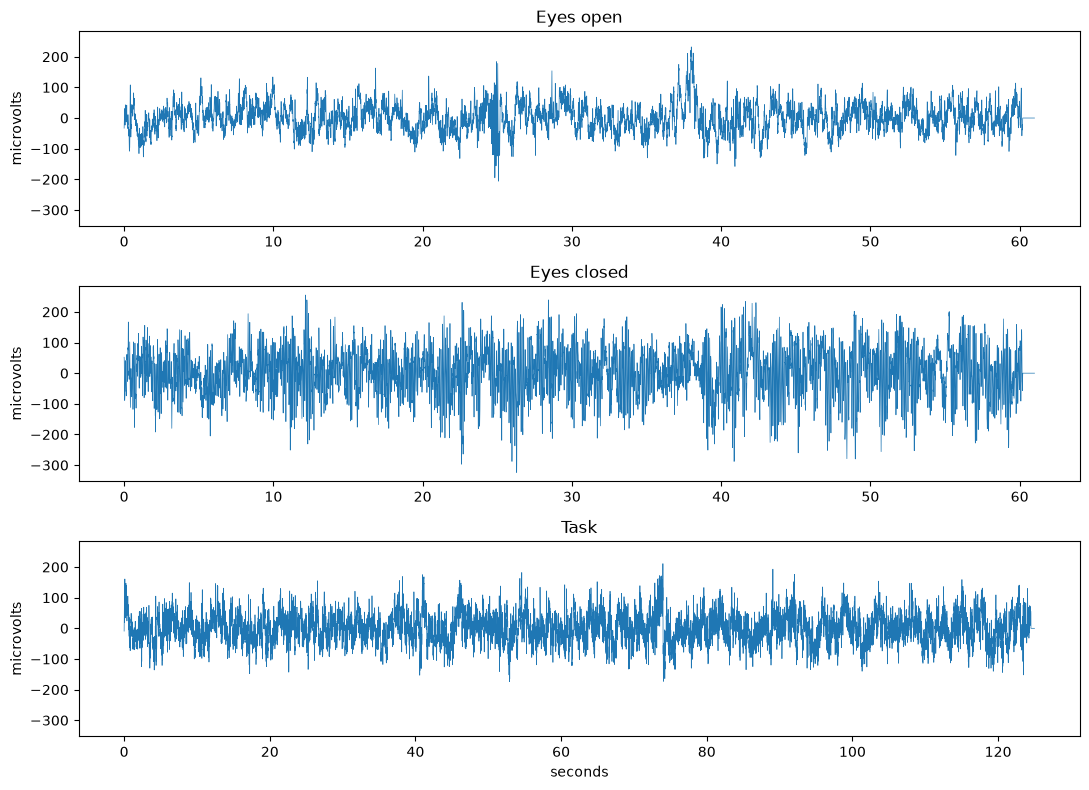

In [3]:
sig, fs = {}, {}
for name, f in FILES.items():
    sig[name], fs[name] = read_edf(f, CHANNEL)
    print(f"{name}: n = {len(sig[name])}, fs = {fs[name]} Hz")

fig, ax = plt.subplots(3, 1, figsize=(11, 8), sharey=True)
for a, (name, x) in zip(ax, sig.items()):
    a.plot(np.arange(len(x)) / fs[name], x, lw=0.5)
    a.set_title(name)
    a.set_ylabel("microvolts")
ax[-1].set_xlabel("seconds")
plt.tight_layout()
plt.show()

Eyes closed shows large, regular oscillations and the widest range of values. Eyes open is smaller, with a few bursts. The task series has a steady amplitude with no obvious trend, and it is about twice as long as the other two.

B

Eyes open: lambda = 100000
Eyes closed: lambda = 31622.8
Task: lambda = 316228


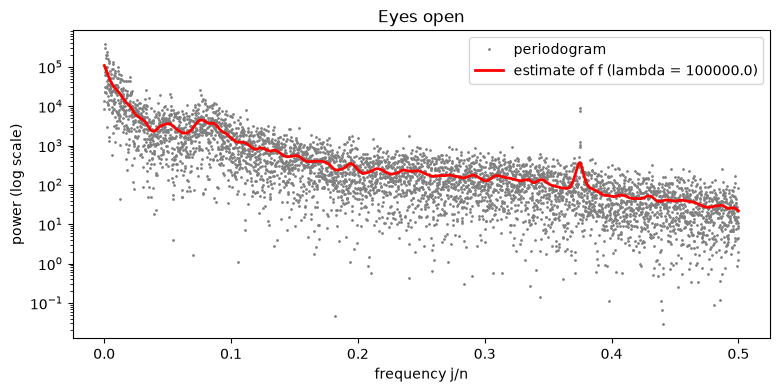

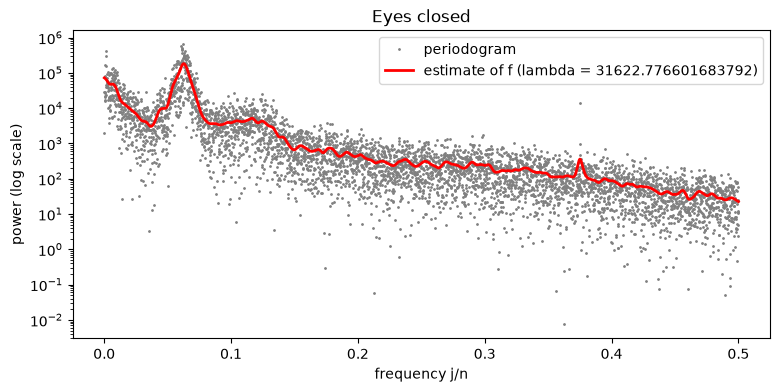

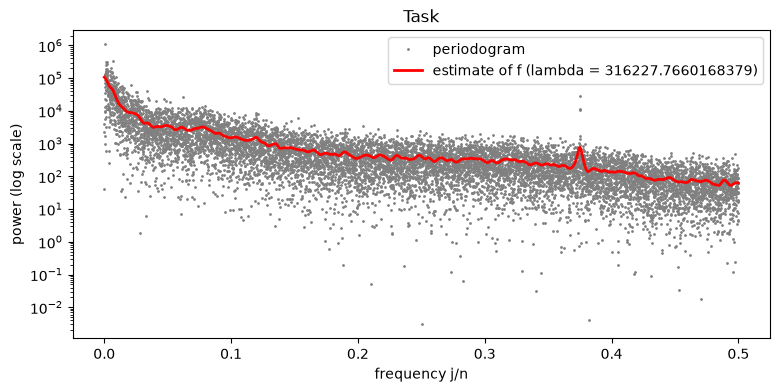

In [5]:
res = {}
for name, x in sig.items():
    freq, I = periodogram(x)
    lam, scores, grid = cv_lambda(I)
    res[name] = dict(freq=freq, I=I, f=np.exp(pen_whittle(I, lam)), lam=lam)
    print(f"{name}: lambda = {lam:g}")

for name, r in res.items():
    plt.figure(figsize=(9, 4))
    plt.semilogy(r["freq"], r["I"], ".", ms=2, color="grey", label="periodogram")
    plt.semilogy(r["freq"], r["f"], "r", lw=2, label=f"estimate of f (lambda = {r['lam']})")
    plt.title(name)
    plt.xlabel("frequency j/n")
    plt.ylabel("power (log scale)")
    plt.legend()
    plt.show()

The chosen lambdas were 100,000 for eyes open, 31,623 for eyes closed and 316,228 for task. In the plots, the red curve follows the overall shape of each periodogram without chasing individual spikes.

C

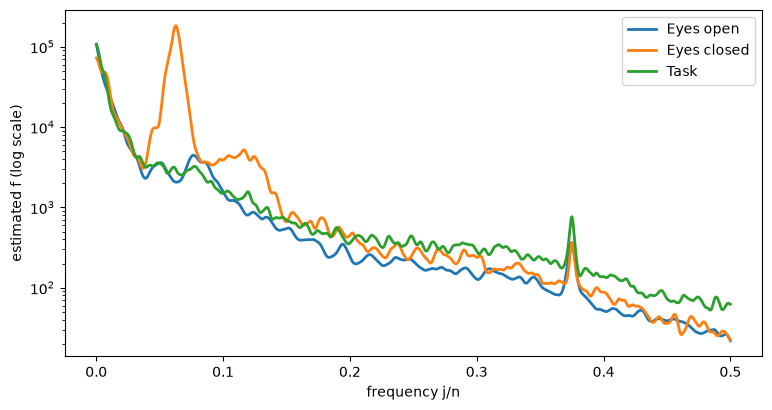

In [6]:
plt.figure(figsize=(9, 4.5))
for name, r in res.items():
    plt.semilogy(r["freq"], r["f"], lw=2, label=name)
plt.xlabel("frequency j/n")
plt.ylabel("estimated f (log scale)")
plt.legend()
plt.show()

Eyes closed has by far the highest power, with a sharp peak near 10 Hz (the alpha rhythm) that is much weaker in eyes open and task. Eyes open and task are similar at low frequencies, and task has somewhat more power at higher frequencies. All three decay as frequency increases. All three also show a narrow spike at j/n = 0.375 (60 Hz), most likely electrical interference.